# k-NN vs Voting V7

For V7, I wanted to see if letting the neural networks vote on slightly more images would help. I kept the same distance gaps as V6 and changed the cutoff from 30% to 35%. I chose this cutoff after looking at the same validation set.

First, I imported the libraries and functions I'll need.

In [1]:
from pathlib import Path
from time import perf_counter
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

project_root = Path.cwd()
if not (project_root / 'src').is_dir():
    project_root = project_root.parent
sys.path.insert(0, str(project_root))
from src.data_loader import load_task, split_train_val
from src.models.knn import KNNClassifier, euclidean_distance

result_dir = project_root / 'results/model_comparison'
result_dir.mkdir(parents=True, exist_ok=True)

I loaded the same image split and checked the saved V5, V6 and NN predictions against the validation labels.

In [2]:
X, y, X_test, test_ids = load_task('image')
X_train, X_val, y_train, y_val = split_train_val(X, y, val_fraction=0.2, seed=42)
assert X_train.shape == (16000, 500) and X_val.shape == (4000, 500)
assert X.shape == (20000, 500) and X_test.shape == (5000, 500)
assert X.dtype == X_train.dtype == X_val.dtype == X_test.dtype == np.float32
v6_gaps = pd.read_csv(result_dir / 'knn_vs_voting_v6_gap_validation.csv')
v5_vote = pd.read_csv(result_dir / 'knn_vs_voting_v5_image_validation.csv')
v6_vote = pd.read_csv(result_dir / 'knn_vs_voting_v6_image_validation.csv')
nn3 = pd.read_csv(project_root / 'results/image/nn_v3_validation.csv')
nn4 = pd.read_csv(project_root / 'results/image/nn_v4_validation.csv')
for frame in [v5_vote, v6_vote, nn3, nn4]:
    assert frame.columns.tolist() == ['validation_index', 'actual_label', 'predicted_label']
    assert len(frame) == 4000 and not frame.isna().any().any()
    assert frame.validation_index.is_unique
    assert np.array_equal(frame.validation_index, np.arange(4000))
    assert np.array_equal(frame.actual_label, y_val)
    for column in frame.columns:
        assert pd.api.types.is_integer_dtype(frame[column])
    assert frame.actual_label.between(0, 49).all() and frame.predicted_label.between(0, 49).all()
assert len(v6_gaps) == 4000 and not v6_gaps.isna().any().any()
assert np.array_equal(v6_gaps.validation_index, np.arange(4000))
assert np.array_equal(v6_gaps.actual_label, y_val)
assert np.array_equal(v6_gaps.nn3_label, nn3.predicted_label)
assert np.array_equal(v6_gaps.nn4_label, nn4.predicted_label)

I kept V6's feature transformation and calculated the same gap between the nearest image and the nearest image from another class.

In [3]:
def normalize_rows(features):
    lengths = np.linalg.norm(features, axis=1, keepdims=True)
    assert np.isfinite(features).all() and np.isfinite(lengths).all() and (lengths > 0).all()
    normalized = features / lengths
    assert normalized.shape == features.shape and normalized.dtype == np.float32
    assert np.allclose(np.linalg.norm(normalized, axis=1), 1, atol=1e-6)
    return normalized


def nearest_class_gaps(model, features):
    nearest_distances = []
    other_distances = []
    gaps = []
    nearest_labels = []
    for position, image in enumerate(features):
        distances = euclidean_distance(image, model.X_train)
        nearest_index = int(np.argmin(distances))
        knn_label = model.y_train[nearest_index]
        other_class = model.y_train != knn_label
        assert other_class.any()
        d1 = distances[nearest_index]
        d_other = np.min(distances[other_class])
        nearest_distances.append(d1)
        other_distances.append(d_other)
        gaps.append(d_other - d1)
        nearest_labels.append(knn_label)
        if (position + 1) % 1000 == 0:
            print('Calculated neighbors for', position + 1, 'images', flush=True)
    return (np.asarray(nearest_distances), np.asarray(other_distances),
            np.asarray(gaps), np.asarray(nearest_labels))

assert (X_train >= 0).all() and (X_val >= 0).all()
sqrt_train = np.sqrt(X_train)
feature_mean = sqrt_train.mean(axis=0)
assert feature_mean.shape == (500,) and feature_mean.dtype == np.float32
train_centered = normalize_rows(sqrt_train - 0.5 * feature_mean)
val_centered = normalize_rows(np.sqrt(X_val) - 0.5 * feature_mean)
model = KNNClassifier(k=1, distance_fn=euclidean_distance, voting_method='majority')
model.fit(train_centered, y_train)
start = perf_counter()
validation_distances, validation_other_distances, validation_gaps, knn_predictions = nearest_class_gaps(model, val_centered)
assert np.array_equal(knn_predictions, v6_gaps.knn_label.to_numpy())
assert np.array_equal(model.predict(val_centered[:5]), knn_predictions[:5])
for values in [validation_distances, validation_other_distances, validation_gaps]:
    assert values.shape == (4000,) and values.dtype == np.float32 and np.isfinite(values).all()
assert (validation_gaps >= -1e-6).all()
for values, column in [(validation_distances, 'nearest_distance'),
                       (validation_other_distances, 'other_class_distance'),
                       (validation_gaps, 'distance_gap')]:
    assert np.array_equal(values, v6_gaps[column].to_numpy(dtype=np.float32))
cutoff = np.percentile(validation_gaps[:2000], 35)
print('Validation gap cutoff:', cutoff)
print('All 4000 k-NN labels and distance gaps match V6.')
print(f'Validation neighbors calculated in {perf_counter() - start:.2f} s')

Calculated neighbors for 1000 images
Calculated neighbors for 2000 images
Calculated neighbors for 3000 images
Calculated neighbors for 4000 images
Validation gap cutoff: 0.016974127292633055
All 4000 k-NN labels and distance gaps match V6.
Validation neighbors calculated in 126.41 s


I used the same NN agreement rule, but changed the gap cutoff to the 35th percentile of the first 2000 validation images.

In [4]:
def conditional_vote(knn_labels, gaps, nn3_labels, nn4_labels, cutoff):
    assert len(knn_labels) == len(gaps) == len(nn3_labels) == len(nn4_labels)
    use_nn = (gaps <= cutoff) & (nn3_labels == nn4_labels)
    predictions = knn_labels.copy()
    predictions[use_nn] = nn3_labels[use_nn]
    return predictions, use_nn

v7_predictions, use_nn = conditional_vote(
    knn_predictions, validation_gaps, nn3.predicted_label.to_numpy(),
    nn4.predicted_label.to_numpy(), cutoff)
assert np.array_equal(v7_predictions[~use_nn], knn_predictions[~use_nn])
assert np.array_equal(v7_predictions[use_nn], nn3.predicted_label.to_numpy()[use_nn])
assert ((v7_predictions >= 0) & (v7_predictions <= 49)).all()
validation = pd.DataFrame({'validation_index': np.arange(4000),
    'actual_label': y_val, 'predicted_label': v7_predictions})
validation.to_csv(result_dir / 'knn_vs_voting_v7_image_validation.csv', index=False)
gap_details = pd.DataFrame({'validation_index': np.arange(4000),
    'actual_label': y_val, 'knn_label': knn_predictions,
    'nearest_distance': validation_distances, 'other_class_distance': validation_other_distances,
    'distance_gap': validation_gaps, 'nn3_label': nn3.predicted_label.to_numpy(),
    'nn4_label': nn4.predicted_label.to_numpy(), 'used_nn': use_nn,
    'predicted_label': v7_predictions})
gap_details.to_csv(result_dir / 'knn_vs_voting_v7_gap_validation.csv', index=False)
print('NN agreement and gap cutoff met:', int(use_nn.sum()))
print('Labels changed from k-NN:', int((v7_predictions != knn_predictions).sum()))

NN agreement and gap cutoff met: 580
Labels changed from k-NN: 482


I compared the new result with V5 and V6 using the same validation images, then checked both halves of that split.

In [5]:
rows = []
for name, predictions in [
    ('V5 conditional', v5_vote.predicted_label.to_numpy()),
    ('V6 distance-gap conditional', v6_vote.predicted_label.to_numpy()),
    ('V7 distance-gap conditional', v7_predictions)]:
    correct = int((predictions == y_val).sum())
    rows.append({'candidate': name, 'correct_count': correct,
                 'validation_samples': len(y_val), 'validation_accuracy': correct / len(y_val)})
summary = pd.DataFrame(rows)
summary.to_csv(result_dir / 'knn_vs_voting_v7_summary.csv', index=False)
print(summary.to_string(index=False))
v6_labels = v6_vote.predicted_label.to_numpy()
old_correct = v6_labels == y_val
new_correct = v7_predictions == y_val
print('Labels changed from V6:', int((v7_predictions != v6_labels).sum()))
print('Previously wrong predictions corrected:', int((~old_correct & new_correct).sum()))
print('Previously correct predictions lost:', int((old_correct & ~new_correct).sum()))
print('Net additional correct images:', int(new_correct.sum() - old_correct.sum()))
for start, end in [(0, 2000), (2000, 4000)]:
    old_count = int(old_correct[start:end].sum())
    new_count = int(new_correct[start:end].sum())
    print(f'Validation positions {start}..{end-1}: V6={old_count}/2000 ({old_count/2000:.3%}), '
          f'V7={new_count}/2000 ({new_count/2000:.3%}), gain={new_count-old_count}')

                  candidate  correct_count  validation_samples  validation_accuracy
             V5 conditional           2306                4000              0.57650
V6 distance-gap conditional           2350                4000              0.58750
V7 distance-gap conditional           2363                4000              0.59075
Labels changed from V6: 89
Previously wrong predictions corrected: 30
Previously correct predictions lost: 17
Net additional correct images: 13
Validation positions 0..1999: V6=1178/2000 (58.900%), V7=1185/2000 (59.250%), gain=7
Validation positions 2000..3999: V6=1172/2000 (58.600%), V7=1178/2000 (58.900%), gain=6


I plotted the three image accuracies to compare the voting rules.

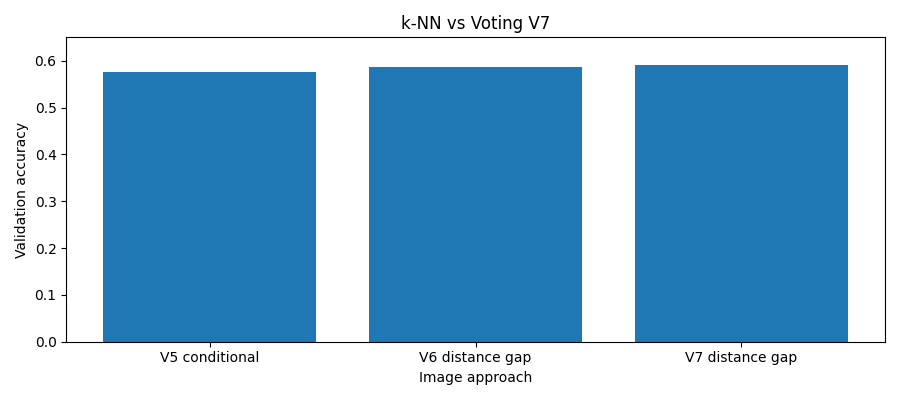

In [6]:
plt.figure(figsize=(9, 4))
plt.bar(['V5 conditional', 'V6 distance gap', 'V7 distance gap'], summary.validation_accuracy)
plt.xlabel('Image approach')
plt.ylabel('Validation accuracy')
plt.title('k-NN vs Voting V7')
plt.ylim(0, 0.65)
plt.tight_layout()
plt.savefig(result_dir / 'knn_vs_voting_v7_accuracy.png')
plt.show()

I kept NN V3 for sentiment and calculated the equal average of the two task accuracies.

In [7]:
sentiment = pd.read_csv(project_root / 'results/sentiment/nn_v3_validation.csv')
sentiment_X, sentiment_y, sentiment_X_test, sentiment_test_ids = load_task('sentiment')
_, _, _, sentiment_y_val = split_train_val(
    sentiment_X, sentiment_y,
    val_fraction=0.2, seed=42)
assert len(sentiment) == 2400 and not sentiment.isna().any().any()
assert sentiment.validation_index.is_unique
assert np.array_equal(sentiment.validation_index, np.arange(2400))
assert np.array_equal(sentiment.actual_label, sentiment_y_val)
for column in ['validation_index', 'actual_label', 'predicted_label']:
    assert pd.api.types.is_integer_dtype(sentiment[column])
assert sentiment.predicted_label.between(0, 2).all()
sentiment_correct = int((sentiment.predicted_label == sentiment.actual_label).sum())
sentiment_accuracy = sentiment_correct / len(sentiment)
image_accuracy = float((v7_predictions == y_val).mean())
combined_accuracy = (image_accuracy + sentiment_accuracy) / 2
print(f'NN V3 sentiment: {sentiment_correct}/{len(sentiment)}, accuracy={sentiment_accuracy!r}')
print('Combined validation accuracy:', combined_accuracy)

NN V3 sentiment: 1639/2400, accuracy=0.6829166666666666
Combined validation accuracy: 0.6368333333333334


I used all 20000 training images to make the test predictions. I calculated a fresh 35th-percentile cutoff from the 5000 test gaps.

In [8]:
X, y, X_test, test_ids = load_task('image')
assert X.shape == (20000, 500) and X_test.shape == (5000, 500)
assert X.dtype == X_test.dtype == np.float32
assert (X >= 0).all() and (X_test >= 0).all()
sqrt_all = np.sqrt(X)
full_feature_mean = sqrt_all.mean(axis=0)
assert full_feature_mean.shape == (500,) and full_feature_mean.dtype == np.float32
all_centered = normalize_rows(sqrt_all - 0.5 * full_feature_mean)
test_centered = normalize_rows(np.sqrt(X_test) - 0.5 * full_feature_mean)
test_model = KNNClassifier(k=1, distance_fn=euclidean_distance, voting_method='majority')
test_model.fit(all_centered, y)
start = perf_counter()
test_distances, test_other_distances, test_gaps, test_knn_labels = nearest_class_gaps(test_model, test_centered)
assert len(test_distances) == len(test_knn_labels) == len(test_ids) == 5000
for values in [test_distances, test_other_distances, test_gaps]:
    assert values.shape == (5000,) and values.dtype == np.float32 and np.isfinite(values).all()
assert (test_gaps >= -1e-6).all()
assert np.array_equal(test_model.predict(test_centered[:5]), test_knn_labels[:5])
test_cutoff = np.percentile(test_gaps, 35)
print('Test gap cutoff:', test_cutoff)
print(f'Test neighbors calculated in {perf_counter() - start:.6f} s')

Calculated neighbors for 1000 images
Calculated neighbors for 2000 images
Calculated neighbors for 3000 images
Calculated neighbors for 4000 images
Calculated neighbors for 5000 images
Test gap cutoff: 0.019642937183380123
Test neighbors calculated in 236.946838 s


I matched NN V3 and V4 by image ID and applied the same conditional rule.

In [9]:
sample = pd.read_csv(project_root / 'data/raw/sample_submission.csv')
text_ids = pd.read_csv(project_root / 'data/raw/sentiment_test.csv', usecols=['id']).id
assert sample.columns.tolist() == ['id', 'label']
assert len(sample) == 10000 and sample.id.is_unique and not sample.isna().any().any()
assert len(set(test_ids)) == 5000 and len(text_ids) == 5000 and text_ids.is_unique
assert all(str(sample_id).startswith('img_') for sample_id in test_ids)
assert text_ids.str.startswith('text_').all()
assert set(test_ids).isdisjoint(set(text_ids))
assert set(sample.id) == set(test_ids) | set(text_ids)
is_image = sample.id.isin(test_ids)
is_text = sample.id.isin(text_ids)

def align_submission(path, ids):
    frame = pd.read_csv(path)
    assert frame.columns.tolist() == ['id', 'label']
    assert len(frame) == 10000 and frame.id.is_unique and not frame.isna().any().any()
    assert set(frame.id) == set(sample.id)
    assert pd.api.types.is_integer_dtype(frame.label)
    assert frame.loc[frame.id.isin(test_ids), 'label'].between(0, 49).all()
    assert frame.loc[frame.id.isin(text_ids), 'label'].between(0, 2).all()
    aligned = pd.DataFrame({'id': ids}).merge(frame, on='id', how='left', sort=False, validate='one_to_one')
    assert aligned.id.tolist() == list(ids) and not aligned.isna().any().any()
    return aligned

nn3_images = align_submission(project_root / 'submission/nn/submission_v3_nn.csv', test_ids)
nn4_images = align_submission(project_root / 'submission/nn/submission_v4_nn.csv', test_ids)
test_predictions, test_use_nn = conditional_vote(test_knn_labels, test_gaps,
    nn3_images.label.to_numpy(), nn4_images.label.to_numpy(), test_cutoff)
assert np.array_equal(test_predictions[~test_use_nn], test_knn_labels[~test_use_nn])
assert np.array_equal(test_predictions[test_use_nn], nn3_images.label.to_numpy()[test_use_nn])
print('Image labels changed from k-NN:', int((test_predictions != test_knn_labels).sum()))
print('Test NN agreement and gap cutoff met:', int(test_use_nn.sum()))

Image labels changed from k-NN: 562
Test NN agreement and gap cutoff met: 711


Finally, I combined the image predictions with NN V3 sentiment, saved the Kaggle CSV and compared it with V6 by ID.

In [10]:
image_predictions = pd.DataFrame({'id': test_ids, 'label': test_predictions})
sentiment_predictions = align_submission(project_root / 'submission/nn/submission_v3_nn.csv', text_ids)
predictions = pd.concat([image_predictions, sentiment_predictions], ignore_index=True)
assert len(predictions) == 10000 and predictions.id.is_unique
submission = sample[['id']].merge(predictions, on='id', how='left', sort=False, validate='one_to_one')
assert submission.columns.tolist() == ['id', 'label']
assert submission.id.tolist() == sample.id.tolist()
assert not submission.isna().any().any() and pd.api.types.is_integer_dtype(submission.label)
assert is_image.sum() == is_text.sum() == 5000
assert submission.loc[is_image, 'label'].between(0, 49).all()
assert submission.loc[is_text, 'label'].between(0, 2).all()
assert np.array_equal(submission.loc[is_text, 'label'],
    align_submission(project_root / 'submission/nn/submission_v3_nn.csv', sample.id).loc[is_text, 'label'])
submission_dir = project_root / 'submission/model_combinations'
submission_dir.mkdir(parents=True, exist_ok=True)
submission_path = submission_dir / 'submission_knn_vs_voting_v7.csv'
submission.to_csv(submission_path, index=False)
pd.testing.assert_frame_equal(pd.read_csv(submission_path), submission)
print('Saved', len(submission), 'predictions to', submission_path.relative_to(project_root))
previous = align_submission(project_root / 'submission/model_combinations/submission_knn_vs_voting_v6.csv', sample.id)
changed = submission.label != previous.label
changed_images = int((changed & is_image).sum())
changed_sentiment = int((changed & is_text).sum())
print('Changed image labels compared with V6:', changed_images)
print('Changed sentiment labels compared with V6:', changed_sentiment)
assert changed_images > 0 and changed_sentiment == 0

Saved 10000 predictions to submission\model_combinations\submission_knn_vs_voting_v7.csv
Changed image labels compared with V6: 75
Changed sentiment labels compared with V6: 0


V7 got 2363/4000 images correct (59.075%), compared with 2350 for V6, and reached 63.6833% combined validation accuracy. I'll compare its Kaggle score before deciding if the cutoff change helped.